# COM7022 Machine Learning: Product Clustering for an E-commerce Catalogue

**Student ID:** 25199053 · **Module:** COM7022 Machine Learning · **Task 1:** Practical Project

This notebook groups the product listings in `Sales-[5444].csv` by their characteristics and sales performance. It follows the steps of a standard machine learning investigation:

1. Data import
2. Descriptive statistics and data quality checks
3. Pre-processing
4. Feature selection
5. Principal Component Analysis (PCA)
6. K-Means
7. Hierarchical clustering
8. DBSCAN
9. Model comparison and validation
10. Final model and cluster profiles

**How to run on Google Colab:** upload `Sales-[5444].csv` into the Colab file panel (or let the upload cell below ask for it), then choose *Runtime > Run all*. All figures and tables are saved into an `output/` folder next to the notebook. Random seeds are fixed so the results repeat.

## 0. Set-up

In [1]:
# Standard libraries
import os
import re
import json
import warnings
from pathlib import Path

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

# Machine learning tools
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import skew

warnings.filterwarnings("ignore", category=FutureWarning)

# One seed for every random step, so a re-run gives the same numbers
SEED = 42
np.random.seed(SEED)

print("Python libraries used in this run:")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python libraries used in this run:
pandas 3.1.0 | numpy 2.4.6 | scikit-learn 1.9.1 | scipy 1.17.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# Arden University palette (Midnight / Tiffany), the same visual system used in my earlier modules
MIDNIGHT = "#002B49"
TIFFANY = "#66C9BA"
TIFFANY_DEEP = "#3AA89A"
MIDNIGHT_SOFT = "#1A4A6B"
TEAL = "#0E7C8B"
MIST = "#E6F5F2"
PAPER = "#F7FAFB"
MUTE = "#5A6B75"
GRID = "#D5DEE3"
NOISE_GREY = "#A7B4BC"

# Cluster colours in a fixed order (five at most, then the chart should be split)
CLUSTER_COLOURS = [MIDNIGHT, TIFFANY_DEEP, TEAL, MIDNIGHT_SOFT, TIFFANY]
ARDEN_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list(
    "arden", [MIST, TIFFANY, TIFFANY_DEEP, MIDNIGHT_SOFT, MIDNIGHT])
ARDEN_DIVERGING = matplotlib.colors.LinearSegmentedColormap.from_list(
    "arden_div", [TIFFANY_DEEP, MIST, "#FFFFFF", "#D9E3EA", MIDNIGHT])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Aptos", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.facecolor": "white",
    "axes.facecolor": PAPER,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MIDNIGHT,
    "axes.titlecolor": MIDNIGHT,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlepad": 15,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "xtick.color": MUTE,
    "ytick.color": MUTE,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "savefig.bbox": "tight",
})

# Output folders for the figures and tables used in the report
OUTPUT_DIR = Path("output")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    # Save every chart with the same settings so the report pack is consistent
    fig.savefig(FIG_DIR / filename)
    print("Saved:", FIG_DIR / filename)


def save_table(table, filename):
    table.to_csv(TABLE_DIR / filename)
    print("Saved:", TABLE_DIR / filename)

## 1. Data import

The notebook first looks for the CSV next to the notebook. On Colab, if the file has not been uploaded yet, it opens an upload dialog. The import of `google.colab` is wrapped in `try` so the same notebook also runs on a normal Jupyter install.

In [3]:
DATA_FILE = "Sales-[5444].csv"
candidate_paths = [Path(DATA_FILE), Path("..") / DATA_FILE, Path("/content") / DATA_FILE]

data_path = None
for path in candidate_paths:
    if path.exists():
        data_path = path
        break

if data_path is None:
    try:
        from google.colab import files  # only available on Colab
        print("CSV not found. Please upload", DATA_FILE)
        uploaded = files.upload()
        data_path = Path(list(uploaded.keys())[0])
    except ImportError:
        raise FileNotFoundError("Place " + DATA_FILE + " next to this notebook.")

raw = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Shape:", raw.shape[0], "rows x", raw.shape[1], "columns")
raw.head()

Loaded: Sales-[5444].csv
Shape: 1000 rows x 10 columns


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


In [4]:
# Column types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


**Unit of observation.** Each row is one product listing (a seller's offer for one fragrance product). The clustering therefore groups *listings*, not brands or customers. The columns are product information (`Item_Name` = brand, `details`, `Catatory`), pricing (`price`, `priceWithCurrency`), availability and sales (`available`, `text`, `sold`), update history (`lastUpdated`) and location (`itemLocation`).

## 2. Descriptive statistics and data quality

In [5]:
# Missing values per column, as counts and percentages
missing = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(1),
})
missing = missing.sort_values("missing_count", ascending=False)
print("Full-row duplicates:", raw.duplicated().sum())
print("Duplicate listing descriptions:", raw["details"].duplicated().sum())
save_table(missing, "table01_missing_values.csv")
missing

Full-row duplicates: 0
Duplicate listing descriptions: 34
Saved: output/tables/table01_missing_values.csv


,missing_count,missing_pct
available,111,11.1
lastUpdated,53,5.3
sold,8,0.8
price,5,0.5
Catatory,3,0.3
text,3,0.3
Item_Name,1,0.1
priceWithCurrency,1,0.1
details,0,0.0
itemLocation,0,0.0


Saved: output/figures/fig01_missing_values.png


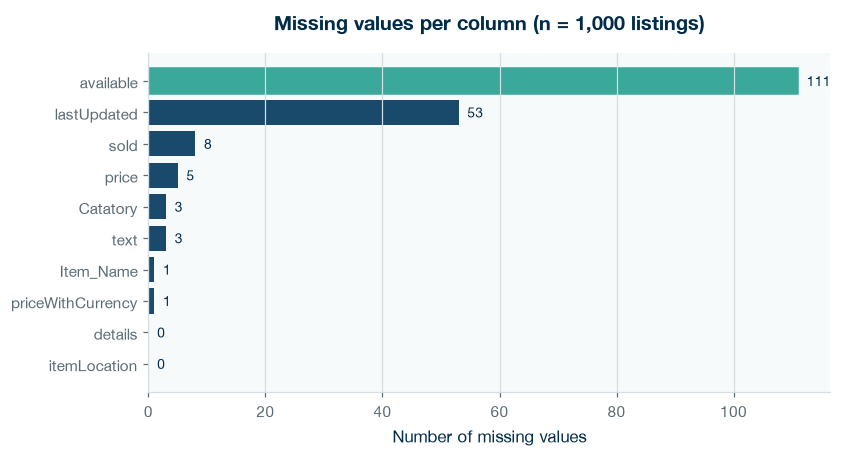

In [6]:
# Figure 1: where the gaps are
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(missing.index[::-1], missing["missing_count"][::-1], color=MIDNIGHT_SOFT)
# Highlight the biggest gap, since it drives a pre-processing decision
bars[-1].set_color(TIFFANY_DEEP)
for bar, value in zip(bars, missing["missing_count"][::-1]):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, str(value),
            va="center", color=MIDNIGHT, fontsize=9)
ax.set_title("Missing values per column (n = 1,000 listings)")
ax.set_xlabel("Number of missing values")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig01_missing_values.png")
plt.show()

In [7]:
# Descriptive statistics for the numeric columns, including skewness
numeric_cols = ["price", "available", "sold"]
desc = raw[numeric_cols].describe().T
desc["median"] = raw[numeric_cols].median()
desc["skewness"] = [skew(raw[c].dropna()) for c in numeric_cols]
desc = desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skewness"]].round(2)
save_table(desc, "table02_descriptive_statistics_raw.csv")
desc

Saved: output/tables/table02_descriptive_statistics_raw.csv


,count,mean,median,std,min,25%,75%,max,skewness
price,995.0,46.43,35.71,35.55,3.0,22.99,59.00,259.09,2.04
available,889.0,20.05,10.00,61.55,2.0,5.00,10.00,842.00,8.15
sold,992.0,775.25,49.50,3211.43,1.0,14.00,324.75,54052.00,9.70


In [8]:
# Text and category columns: how many distinct values, and the most common ones
for col in ["Item_Name", "Catatory", "itemLocation"]:
    print(col, "->", raw[col].nunique(), "distinct values")
print()
print("Category labels (top 15 of", raw["Catatory"].nunique(), "):")
print(raw["Catatory"].value_counts().head(15))

Item_Name -> 246 distinct values
Catatory -> 63 distinct values
itemLocation -> 276 distinct values

Category labels (top 15 of 63 ):
Catatory
Eau de Toilette    444
Eau de Parfum      285
Eau de Cologne      56
Perfume             50
Fragrances          32
Eau De Parfum       15
Parfum              13
Eau de Perfume      10
Eau De Toilette      9
Gift Sets            6
Cologne              5
PARFUM               4
Body Spray           4
/                    3
Aftershave           3
Name: count, dtype: int64


In [9]:
# The 'text' column holds the availability and sales wording shown on the listing.
# Replacing digits with N shows the small number of patterns behind 1,000 rows.
patterns = raw["text"].fillna("<missing>").str.split("/").str[0].str.strip()
patterns = patterns.str.replace(r"\d[\d,]*", "N", regex=True)
print(patterns.value_counts())
print()
print("Currencies in priceWithCurrency:")
print(raw["priceWithCurrency"].str.extract(r"^([A-Z]+ ?\$)")[0].value_counts())

text
N available                                     592
More than N available                           297
Limited quantity available                       59
Last One                                         47
<missing>                                         3
More than N lots available (N items per lot)      2
Name: count, dtype: int64

Currencies in priceWithCurrency:
0
US $    996
C $       3
Name: count, dtype: int64


**What the checks show.**

- There are no full-row duplicates, so no rows need to be removed for that reason.
- `price` and `sold` are both right-skewed, `sold` extremely so (a few listings sold tens of thousands of units while the median is about 50). Distance-based clustering would be dominated by those few rows unless the scale is compressed.
- `available` has the largest gap. The `text` column explains it: the missing rows are listings showing *"Limited quantity available"*, *"Last One"* or lot-based wording instead of a number. It also shows that *"More than 10 available"* was stored as 10, so the stock figure is **capped**, not exact.
- `Catatory` has dozens of labels that are spelling or capitalisation variants of the same product type.
- `priceWithCurrency` contains three Canadian-dollar prices among US-dollar prices.

Saved: output/figures/fig02_raw_distributions.png


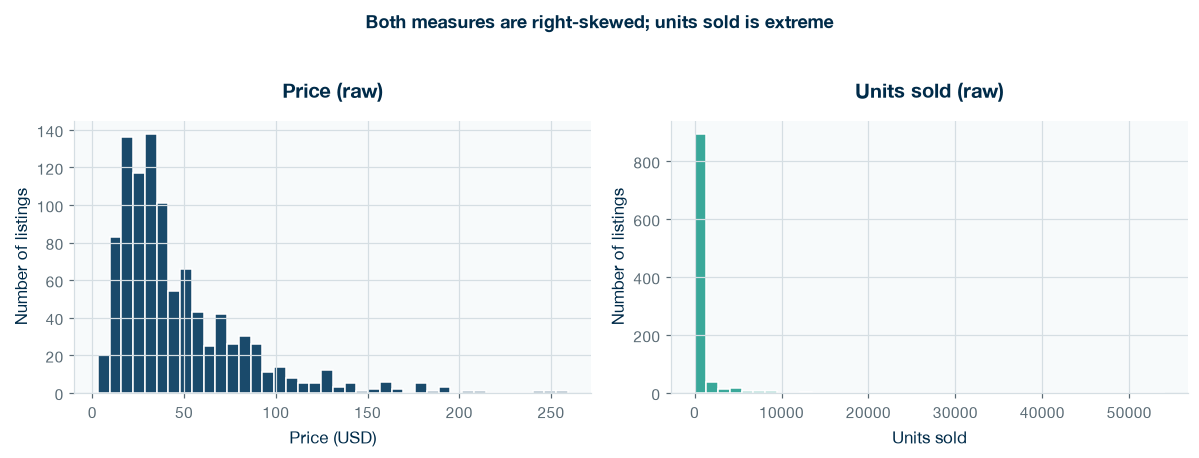

In [10]:
# Figure 2: raw distributions of price and units sold
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw["price"].dropna(), bins=40, color=MIDNIGHT_SOFT, edgecolor="white")
axes[0].set_title("Price (raw)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Number of listings")
axes[1].hist(raw["sold"].dropna(), bins=40, color=TIFFANY_DEEP, edgecolor="white")
axes[1].set_title("Units sold (raw)")
axes[1].set_xlabel("Units sold")
axes[1].set_ylabel("Number of listings")
fig.suptitle("Both measures are right-skewed; units sold is extreme", color=MIDNIGHT, fontweight="bold", y=1.03)
fig.tight_layout()
save_figure(fig, "fig02_raw_distributions.png")
plt.show()

## 3. Pre-processing

Every cleaning step below is recorded in a small log, so the before and after counts can be checked. The guiding rule is to **recover** values from other columns of the same row before imputing, and to impute only where the gap is small and the reason is understood.

In [11]:
df = raw.copy()
cleaning_log = []


def log_step(step, rows_affected, note):
    cleaning_log.append({"step": step, "rows_affected": int(rows_affected), "note": note})


# 3.1 Price: recover missing prices from priceWithCurrency (same listing, same number)
price_from_text = df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0]
price_from_text = price_from_text.str.replace(",", "").astype(float)
recovered = df["price"].isna() & price_from_text.notna()
df.loc[recovered, "price"] = price_from_text[recovered]
log_step("Recover price from priceWithCurrency", recovered.sum(), "Exact same value, only stored in text form")

# Check: where both exist, do they agree?
both = df["price"].notna() & price_from_text.notna()
print("Price disagreements where both exist:", (abs(df.loc[both, "price"] - price_from_text[both]) > 0.01).sum())

# 3.2 Currency: convert the three Canadian-dollar prices to USD
# Approximate May 2024 rate (1 CAD ~ 0.73 USD). Only 3 rows, so the exact rate barely matters.
CAD_TO_USD = 0.73
is_cad = df["priceWithCurrency"].fillna("").str.startswith("C")
df.loc[is_cad, "price"] = (df.loc[is_cad, "price"] * CAD_TO_USD).round(2)
log_step("Convert CAD prices to USD", is_cad.sum(), "Fixed rate 0.73, documented approximation")

Price disagreements where both exist: 0


In [12]:
# 3.3 Units sold: recover from the 'text' column ("... / 116 sold")
sold_from_text = df["text"].str.extract(r"([\d,]+) sold")[0].str.replace(",", "").astype(float)
recovered = df["sold"].isna() & sold_from_text.notna()
df.loc[recovered, "sold"] = sold_from_text[recovered]
log_step("Recover sold from text", recovered.sum(), "Exact value from the listing wording")

# Check the two sources agree everywhere else
both = df["sold"].notna() & sold_from_text.notna()
print("Sold disagreements where both exist:", (df.loc[both, "sold"] != sold_from_text[both]).sum())

# Listings whose text shows stock but no 'sold' part have not sold yet, so sold = 0
no_sales_yet = df["sold"].isna() & df["text"].notna() & ~df["text"].str.contains("sold", na=False)
df.loc[no_sales_yet, "sold"] = 0
log_step("Set sold = 0 where text shows stock but no sales", no_sales_yet.sum(), "Listing wording omits 'sold' when nothing has sold")

# Rows with no text and no sold value carry no sales or stock information at all
no_info = df["sold"].isna() & df["text"].isna()
print(df.loc[no_info, ["Item_Name", "price", "available", "text", "sold"]])
df = df[~no_info].copy()
log_step("Drop rows with no sales or stock information", no_info.sum(), "Cannot be placed on the sales-performance axis")

Sold disagreements where both exist: 1
              Item_Name   price  available text  sold
405  Jean Paul Gaultier  169.00        NaN  NaN   NaN
686              CHANEL   89.97        NaN  NaN   NaN
899             Bvlgari  250.00        NaN  NaN   NaN


In [13]:
# 3.4 Stock level: rebuild it from the listing wording so every row has a value.
# The marketplace hides exact numbers above 10 ("More than 10 available"), so I cap all
# stock values at 11, meaning "more than 10". This keeps the measure honest and comparable.
text = df["text"].fillna("")
stock = text.str.extract(r"^(\d+) available")[0].astype(float)
stock[text.str.startswith("More than")] = 11
stock[text.str.startswith("Last One")] = 1
capped_above_10 = (stock > 11).sum()
stock = stock.clip(upper=11)

# "Limited quantity available" and lot listings give no number: impute the median, but keep a flag
stock_imputed = stock.isna()
df["stock_imputed"] = stock_imputed.astype(int)
stock = stock.fillna(stock.median())
df["stock_level"] = stock

log_step("Stock: 'More than 10' coded as 11", text.str.startswith("More than").sum(), "Censored value, not exact")
log_step("Stock: explicit values above 10 capped at 11", capped_above_10, "Same scale as the censored rows")
log_step("Stock: 'Last One' coded as 1", text.str.startswith("Last One").sum(), "Wording means one unit left")
log_step("Stock: median imputation", stock_imputed.sum(), "Limited quantity / lot wording; flagged in stock_imputed")
print(df["stock_level"].value_counts().sort_index())

stock_level
1.0      47
2.0      55
3.0     109
4.0      46
5.0      62
6.0      43
7.0      34
8.0      45
9.0      98
10.0     44
11.0    414
Name: count, dtype: int64


In [14]:
# 3.5 Product type: collapse the messy category labels into six groups


def group_category(label):
    if pd.isna(label):
        return "Other"
    s = str(label).strip().lower()
    if s in ["", "/", "y", "does not apply", "unknown", "various", "assorted"]:
        return "Other"
    if "," in s or "/" in s:
        return "Other"                       # listings that name several types at once
    if "toil" in s or s == "edt":
        return "Eau de Toilette"             # includes the misspelling 'toillette'
    if "eau de parfum" in s or "eau de perfume" in s:
        return "Eau de Parfum"
    if "parfum" in s or "extrait" in s or "elixir" in s:
        return "Parfum / Extrait"
    if "cologne" in s or s == "edc":
        return "Cologne"
    if "perfume" in s or "fragrance" in s:
        return "Generic fragrance"
    return "Other"                           # body sprays, oils, deodorants, gift sets


df["product_type"] = df["Catatory"].apply(group_category)
print("Raw labels:", df["Catatory"].nunique(), "-> groups:", df["product_type"].nunique())
print(df["product_type"].value_counts())
log_step("Collapse category labels into 6 product types", df["Catatory"].notna().sum(), "Case, spelling and wording variants")

# 3.6 Brand: tidy whitespace; a missing brand is treated as 'Unbranded'
df["brand"] = df["Item_Name"].fillna("Unbranded").str.strip()
log_step("Missing brand set to 'Unbranded'", df["Item_Name"].isna().sum(), "Single row")

# 3.7 Location: keep the country (last part of 'City, State, Country')
df["country"] = df["itemLocation"].str.split(",").str[-1].str.strip()
df["ships_from_us"] = (df["country"] == "United States").astype(int)

# 3.8 Last update: parse dates (two month formats) and turn them into 'days since update'
dates = pd.to_datetime(df["lastUpdated"].str.replace(r" P[DS]T", "", regex=True), format="mixed", errors="coerce")
df["days_since_update"] = (dates.max() - dates).dt.total_seconds() / 86400
print("Unparsed or missing dates:", dates.isna().sum(), "| latest update:", dates.max())

# 3.9 Bottle size in ounces, parsed from the description (used for profiling, not clustering)
size = df["details"].str.extract(r"(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz", flags=re.IGNORECASE)[0].astype(float)
df["size_oz"] = size.where(size.between(0.3, 8.5))   # ignore implausible parses
print("Bottle size found for", df["size_oz"].notna().sum(), "listings")

Raw labels: 63 -> groups: 6


product_type
Eau de Toilette      459
Eau de Parfum        312
Generic fragrance     87
Cologne               69
Other                 41
Parfum / Extrait      29
Name: count, dtype: int64


Unparsed or missing dates:

 50 | latest update: 2024-05-24 10:27:08
Bottle size found for 857 listings


In [15]:
# 3.10 Transform the skewed measures. log(1 + x) keeps zero sales valid (log of 0 is undefined).
df["log_price"] = np.log1p(df["price"])
df["log_sold"] = np.log1p(df["sold"])

skew_table = pd.DataFrame({
    "skew_before": [skew(df["price"]), skew(df["sold"])],
    "skew_after_log": [skew(df["log_price"]), skew(df["log_sold"])],
}, index=["price", "sold"]).round(2)
print(skew_table)

# Outliers: count them with the 1.5 x IQR rule on the raw scale, but keep them.
# Best-selling listings are exactly what the business wants to find, so removing them would be wrong.
q1, q3 = df["sold"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print("Listings above the sold upper fence (" + str(round(upper_fence)) + "):", (df["sold"] > upper_fence).sum())
log_step("Log-transform price and sold", len(df), "Outliers kept; log scale limits their pull on distances")

cleaning_table = pd.DataFrame(cleaning_log)
save_table(cleaning_table, "table03_cleaning_log.csv")
print("Rows after cleaning:", len(df))
cleaning_table

       skew_before  skew_after_log
price         1.97            0.09
sold          9.72            0.52
Listings above the sold upper fence (784): 137
Saved: output/tables/table03_cleaning_log.csv
Rows after cleaning: 997


,step,rows_affected,note
0,Recover price from priceWithCurrency,5,"Exact same value, only stored in text form"
1,Convert CAD prices to USD,3,"Fixed rate 0.73, documented approximation"
2,Recover sold from text,2,Exact value from the listing wording
3,Set sold = 0 where text shows stock but no sales,3,Listing wording omits 'sold' when nothing has ...
4,Drop rows with no sales or stock information,3,Cannot be placed on the sales-performance axis
5,Stock: 'More than 10' coded as 11,299,"Censored value, not exact"
6,Stock: explicit values above 10 capped at 11,115,Same scale as the censored rows
7,Stock: 'Last One' coded as 1,47,Wording means one unit left
8,Stock: median imputation,62,Limited quantity / lot wording; flagged in sto...
9,Collapse category labels into 6 product types,994,"Case, spelling and wording variants"


Saved: output/figures/fig03_transformed_distributions.png


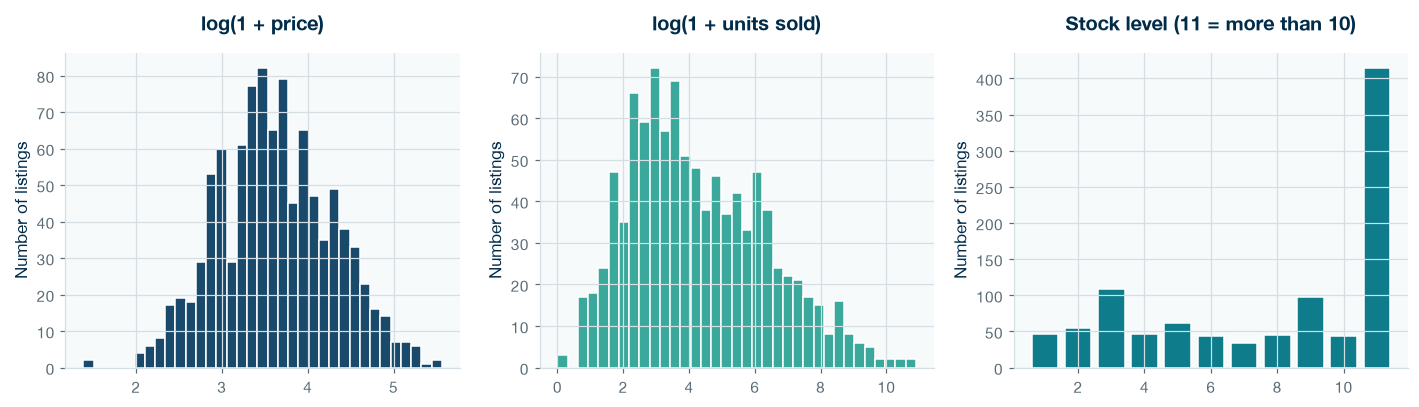

In [16]:
# Figure 3: distributions after the log transform
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(df["log_price"], bins=35, color=MIDNIGHT_SOFT, edgecolor="white")
axes[0].set_title("log(1 + price)")
axes[1].hist(df["log_sold"], bins=35, color=TIFFANY_DEEP, edgecolor="white")
axes[1].set_title("log(1 + units sold)")
axes[2].bar(df["stock_level"].value_counts().sort_index().index,
            df["stock_level"].value_counts().sort_index().values, color=TEAL, edgecolor="white")
axes[2].set_title("Stock level (11 = more than 10)")
for ax in axes:
    ax.set_ylabel("Number of listings")
fig.tight_layout()
save_figure(fig, "fig03_transformed_distributions.png")
plt.show()

In [17]:
# Descriptive statistics after cleaning (these are the numbers the models see, before scaling)
clean_desc = df[["price", "sold", "stock_level", "log_price", "log_sold", "days_since_update", "size_oz"]].describe().T
clean_desc["skewness"] = [skew(df[c].dropna()) for c in clean_desc.index]
clean_desc = clean_desc.round(2)
save_table(clean_desc, "table04_descriptive_statistics_clean.csv")
clean_desc

Saved: output/tables/table04_descriptive_statistics_clean.csv


,count,mean,std,min,25%,50%,75%,max,skewness
price,997.0,46.07,34.75,3.00,22.99,35.62,58.99,259.09,1.97
sold,997.0,771.63,3203.77,0.00,14.00,49.00,322.00,54052.00,9.72
stock_level,997.0,7.73,3.53,1.00,4.00,9.00,11.00,11.00,-0.57
log_price,997.0,3.63,0.67,1.39,3.18,3.60,4.09,5.56,0.09
log_sold,997.0,4.29,2.08,0.00,2.71,3.91,5.78,10.90,0.52
days_since_update,947.0,8.54,32.06,0.00,0.43,1.75,6.08,581.67,12.94
size_oz,857.0,3.58,1.21,0.33,3.30,3.40,3.70,8.00,0.86


## 4. Feature selection

The brief asks for groups based on **product characteristics and sales performance**. The candidate numeric features are listed below. Categorical columns (brand with 240+ values, product type, country) are kept for *describing* clusters afterwards rather than for building them, because one-hot columns mixed with continuous measures distort Euclidean distance and would let a single brand or country dominate the result.

Saved: output/figures/fig04_feature_correlation.png


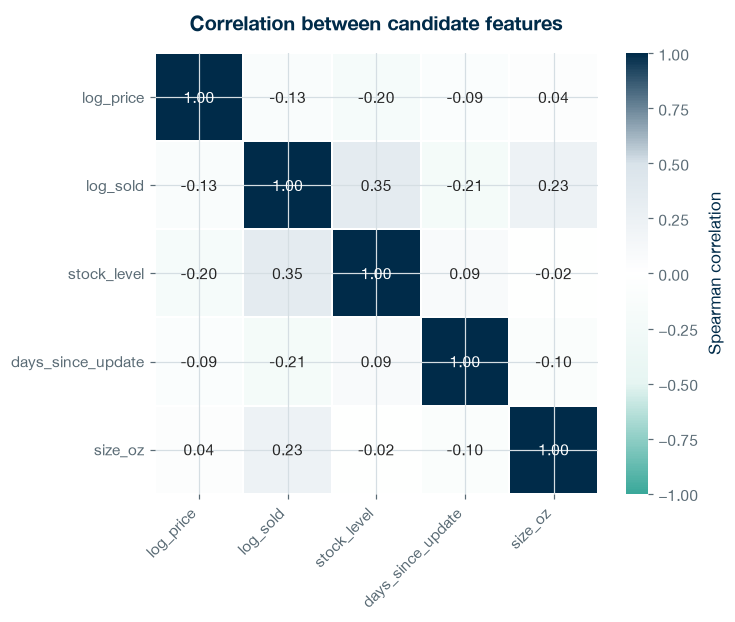

In [18]:
candidates = ["log_price", "log_sold", "stock_level", "days_since_update", "size_oz"]
corr = df[candidates].corr(method="spearman")

# Figure 4: Spearman correlation between candidate features
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=ARDEN_DIVERGING, vmin=-1, vmax=1,
            linewidths=1, linecolor="white", cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between candidate features")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save_figure(fig, "fig04_feature_correlation.png")
plt.show()

In [19]:
# Compare feature sets on the same footing: K-Means silhouette for k = 2..6.
# Rows with missing values in optional features are filled with the median only for this comparison.
feature_sets = {
    "A: price + sold": ["log_price", "log_sold"],
    "B: price + sold + stock": ["log_price", "log_sold", "stock_level"],
    "C: B + days since update": ["log_price", "log_sold", "stock_level", "days_since_update"],
    "D: B + bottle size": ["log_price", "log_sold", "stock_level", "size_oz"],
    "E: B + days + size": ["log_price", "log_sold", "stock_level", "days_since_update", "size_oz"],
}

rows = []
for name, cols in feature_sets.items():
    data = df[cols].fillna(df[cols].median())
    X_try = StandardScaler().fit_transform(data)
    row = {"feature_set": name, "n_features": len(cols)}
    for k in range(2, 7):
        labels_try = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_try)
        row["k=" + str(k)] = round(silhouette_score(X_try, labels_try), 3)
    rows.append(row)

feature_scan = pd.DataFrame(rows).set_index("feature_set")
save_table(feature_scan, "table05_feature_set_scan.csv")
feature_scan

Saved: output/tables/table05_feature_set_scan.csv


,n_features,k=2,k=3,k=4,k=5,k=6
feature_set,,,,,,
A: price + sold,2,0.351,0.377,0.356,0.351,0.354
B: price + sold + stock,3,0.337,0.297,0.307,0.308,0.297
C: B + days since update,4,0.310,0.315,0.277,0.288,0.284
D: B + bottle size,4,0.274,0.308,0.271,0.272,0.272
E: B + days + size,5,0.256,0.259,0.292,0.255,0.258


**Selected features: `log_price`, `log_sold`, `stock_level` (set B).**

- `log_price` describes the product's market position (budget to premium).
- `log_sold` is the sales-performance measure.
- `stock_level` is the availability status, which the brief lists as a key part of the data and which separates listings that are about to run out from ones with deep stock.
- `days_since_update` and `size_oz` lower the silhouette (Table 5), have gaps of their own, and add little business meaning: most bottles are 3.3 to 3.4 oz, and update dates fall within a few weeks. Set A scores slightly higher, but it ignores availability, which the business case needs, so the small loss in separation is accepted for a more useful segmentation.
- None of the three chosen features are strongly correlated with each other (Figure 4), so none is counted twice.

Because K-Means, Ward and DBSCAN all use Euclidean distance, the features must be on the same scale. I use **z-score standardisation** (mean 0, standard deviation 1). The lessons used min-max normalisation; I test that alternative in Section 9 as a sensitivity check.

In [20]:
FEATURES = ["log_price", "log_sold", "stock_level"]
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("Feature matrix:", X.shape)
print("Means after scaling:", X.mean(axis=0).round(3))
print("Std after scaling:", X.std(axis=0).round(3))

Feature matrix: (997, 3)
Means after scaling: [-0.  0. -0.]
Std after scaling: [1. 1. 1.]


## 5. Principal Component Analysis

With three features PCA is not needed to reduce noise, but it gives a faithful 2D view for plotting clusters and shows which features drive the main directions of variation.

In [21]:
pca = PCA(random_state=SEED)
X_pca_full = pca.fit_transform(X)
explained = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=["PC" + str(i + 1) for i in range(len(FEATURES))]).round(3)
print("Explained variance ratio:", explained.round(3))
print("Cumulative:", explained.cumsum().round(3))
save_table(loadings, "table06_pca_loadings.csv")
loadings

Explained variance ratio: [0.486 0.301 0.213]
Cumulative: [0.486 0.787 1.   ]
Saved: output/tables/table06_pca_loadings.csv


,PC1,PC2,PC3
log_price,-0.421,0.906,0.051
log_sold,0.636,0.335,-0.695
stock_level,0.647,0.260,0.717


Saved: output/figures/fig05_pca_variance_biplot.png


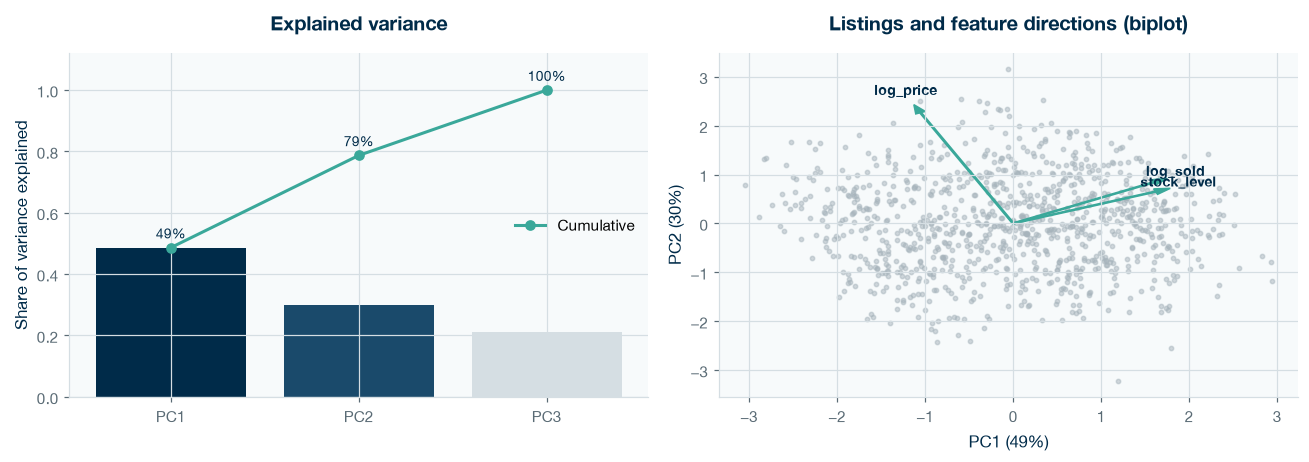

In [22]:
# Figure 5: explained variance (left) and feature loadings on PC1/PC2 (right)
X_2d = X_pca_full[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
pcs = ["PC1", "PC2", "PC3"]
axes[0].bar(pcs, explained, color=[MIDNIGHT, MIDNIGHT_SOFT, GRID])
axes[0].plot(pcs, explained.cumsum(), color=TIFFANY_DEEP, marker="o", linewidth=2, label="Cumulative")
for i, v in enumerate(explained.cumsum()):
    axes[0].text(i, v + 0.03, str(round(v * 100)) + "%", ha="center", color=MIDNIGHT, fontsize=9)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Share of variance explained")
axes[0].set_title("Explained variance")
axes[0].legend(loc="center right")

axes[1].scatter(X_2d[:, 0], X_2d[:, 1], s=8, color=NOISE_GREY, alpha=0.5)
for i, feature in enumerate(FEATURES):
    axes[1].arrow(0, 0, loadings.iloc[i, 0] * 2.5, loadings.iloc[i, 1] * 2.5, color=TIFFANY_DEEP,
                  width=0.02, head_width=0.12)
    axes[1].text(loadings.iloc[i, 0] * 2.9, loadings.iloc[i, 1] * 2.9, feature, color=MIDNIGHT,
                 fontsize=9, fontweight="bold", ha="center")
axes[1].set_xlabel("PC1 (" + str(round(explained[0] * 100)) + "%)")
axes[1].set_ylabel("PC2 (" + str(round(explained[1] * 100)) + "%)")
axes[1].set_title("Listings and feature directions (biplot)")
fig.tight_layout()
save_figure(fig, "fig05_pca_variance_biplot.png")
plt.show()

## 6. K-Means

K-Means needs the number of clusters *k* in advance. I use two signals together: the **elbow** in inertia (within-cluster sum of squares, as taught in Lesson 8) and the **silhouette score**, which measures how much closer each point is to its own cluster than to the next one (range -1 to 1). Several random starts (`n_init=20`) reduce the risk of a poor initial placement of centroids.

In [23]:
k_values = range(2, 11)
kmeans_scan = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels_k = model.fit_predict(X)
    kmeans_scan.append({
        "k": k,
        "inertia": round(model.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels_k), 3),
        "davies_bouldin": round(davies_bouldin_score(X, labels_k), 3),
        "calinski_harabasz": round(calinski_harabasz_score(X, labels_k), 1),
        "smallest_cluster": int(np.bincount(labels_k).min()),
    })
kmeans_scan = pd.DataFrame(kmeans_scan).set_index("k")
save_table(kmeans_scan, "table07_kmeans_k_scan.csv")
kmeans_scan

Saved: output/tables/table07_kmeans_k_scan.csv


,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
k,,,,,
2,1943.0,0.337,1.211,536.7,393
3,1501.0,0.297,1.228,493.4,298
4,1186.7,0.307,1.015,503.3,219
5,974.4,0.308,1.018,513.3,156
6,862.5,0.297,1.053,489.1,141
7,766.7,0.307,1.043,478.7,84
8,691.8,0.296,1.057,469.6,82
9,640.9,0.296,1.029,452.9,59
10,594.6,0.294,1.037,442.0,53


**Choice of k = 4.** No single index gives a sharp answer, which is normal when listings form a continuum rather than well-separated islands.

- The silhouette is highest at k = 2 (0.337), but two groups only split "sells well" from "sells poorly" and hide the price and stock differences the business asked about.
- From k = 2 to k = 4 inertia falls by 39%; after k = 4 each extra cluster saves much less, which is the elbow.
- Davies-Bouldin is lowest at k = 4 (1.015), meaning the four clusters are the most compact relative to their separation of all the options tried.
- At k = 4 the smallest cluster still holds 219 listings (22%), so every segment is large enough to act on. At k = 7 and above, small fragments appear.

So k = 4 is a judgement that balances the indices with usefulness, not the output of one formula.

In [24]:
K_FINAL = 4

Saved: output/figures/fig06_kmeans_elbow_silhouette.png


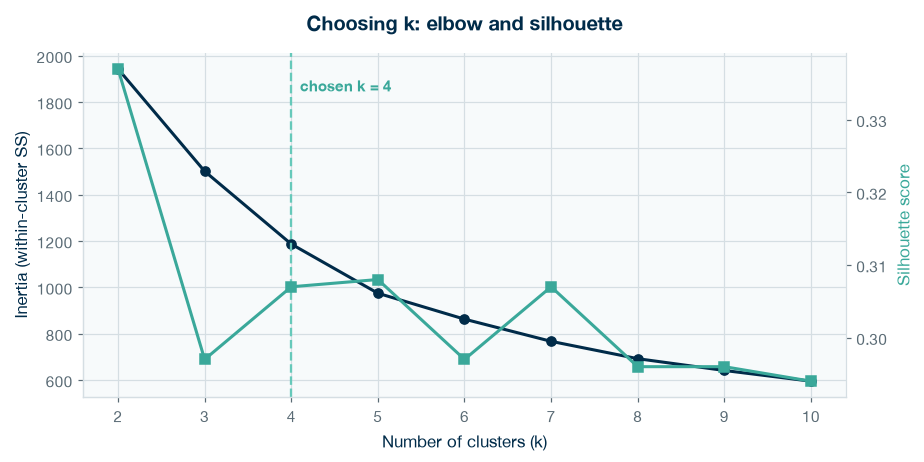

In [25]:
# Figure 6: elbow (inertia) and silhouette against k
fig, ax1 = plt.subplots(figsize=(8.5, 4.3))
ax1.plot(kmeans_scan.index, kmeans_scan["inertia"], color=MIDNIGHT, marker="o", linewidth=2, label="Inertia")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia (within-cluster SS)", color=MIDNIGHT)
ax2 = ax1.twinx()
ax2.plot(kmeans_scan.index, kmeans_scan["silhouette"], color=TIFFANY_DEEP, marker="s", linewidth=2, label="Silhouette")
ax2.set_ylabel("Silhouette score", color=TIFFANY_DEEP)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.axvline(K_FINAL, color=TIFFANY, linestyle="--", linewidth=1.5)
ax1.text(K_FINAL + 0.1, kmeans_scan["inertia"].max() * 0.95, "chosen k = " + str(K_FINAL), color=TIFFANY_DEEP,
         fontweight="bold")
ax1.set_title("Choosing k: elbow and silhouette")
fig.tight_layout()
save_figure(fig, "fig06_kmeans_elbow_silhouette.png")
plt.show()

In [26]:
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED)
df["kmeans"] = kmeans.fit_predict(X)

# Centroids back in original units, which is how a business reader thinks about them
centroids_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centroids["price_usd"] = np.expm1(centroids["log_price"]).round(2)
centroids["units_sold"] = np.expm1(centroids["log_sold"]).round(0)
centroids["stock_level"] = centroids["stock_level"].round(1)
centroids["listings"] = df["kmeans"].value_counts().sort_index().values
print(centroids[["price_usd", "units_sold", "stock_level", "listings"]])

   price_usd  units_sold  stock_level  listings
0      70.88        52.0          9.8       219
1      19.20        30.0          9.8       224
2      29.22      1178.0          9.8       242
3      43.08        18.0          3.2       312


Saved: output/figures/fig07_kmeans_clusters_silhouette.png


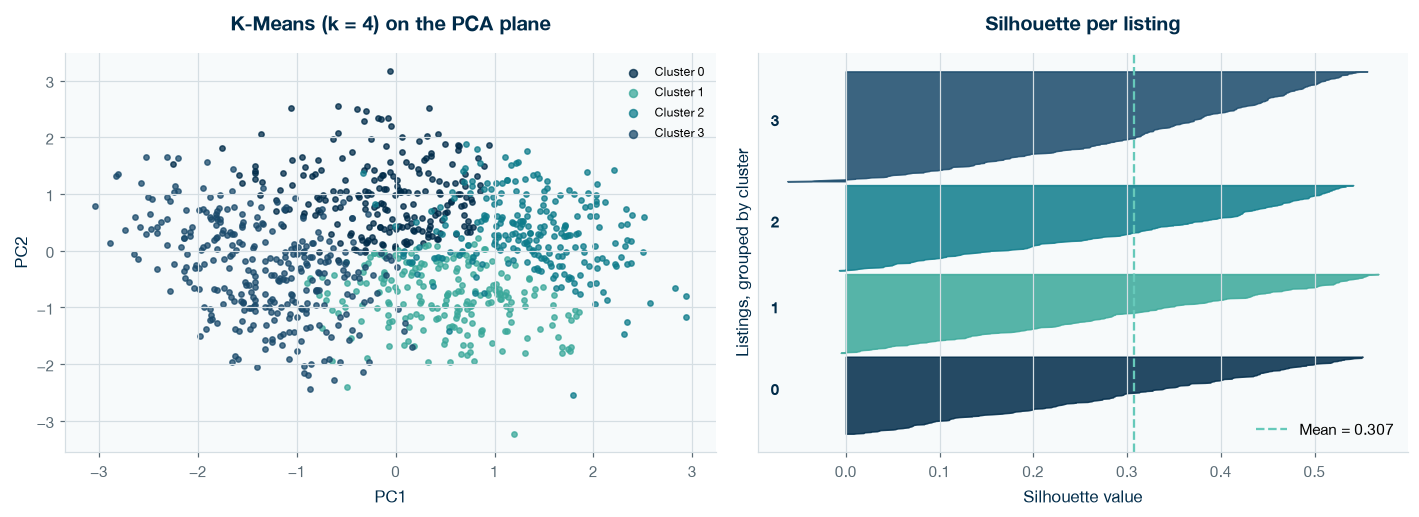

In [27]:
# Figure 7: K-Means clusters on the PCA plane, with a silhouette plot per cluster


def plot_clusters_pca(ax, labels, title, noise_label=None):
    unique = sorted(set(labels))
    for lab in unique:
        mask = labels == lab
        if noise_label is not None and lab == noise_label:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=14, color=NOISE_GREY, marker="x", label="Noise")
        else:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=12, alpha=0.75,
                       color=CLUSTER_COLOURS[lab % len(CLUSTER_COLOURS)], label="Cluster " + str(lab))
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8, markerscale=1.5)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_clusters_pca(axes[0], df["kmeans"].values, "K-Means (k = " + str(K_FINAL) + ") on the PCA plane")

sil_values = silhouette_samples(X, df["kmeans"])
y_lower = 10
for lab in range(K_FINAL):
    values = np.sort(sil_values[df["kmeans"].values == lab])
    y_upper = y_lower + len(values)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, values, color=CLUSTER_COLOURS[lab], alpha=0.85)
    axes[1].text(-0.08, y_lower + len(values) / 2, str(lab), color=MIDNIGHT, fontweight="bold")
    y_lower = y_upper + 10
axes[1].axvline(sil_values.mean(), color=TIFFANY, linestyle="--", label="Mean = " + str(round(sil_values.mean(), 3)))
axes[1].set_xlabel("Silhouette value")
axes[1].set_ylabel("Listings, grouped by cluster")
axes[1].set_yticks([])
axes[1].set_title("Silhouette per listing")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "fig07_kmeans_clusters_silhouette.png")
plt.show()

## 7. Hierarchical clustering

Agglomerative clustering starts with every listing as its own cluster and merges the closest pair step by step. How "closest" is measured is the **linkage**. Following Lesson 9, I compare single, complete, average and Ward linkage on the same Euclidean distances. The **cophenetic correlation** says how faithfully each dendrogram preserves the original pairwise distances (closer to 1 is better).

In [28]:
linkage_methods = ["single", "complete", "average", "ward"]
distances = pdist(X)
linkage_results = {}
linkage_rows = []
for method in linkage_methods:
    Z = linkage(X, method=method)
    linkage_results[method] = Z
    coph_corr, _ = cophenet(Z, distances)
    labels_h = fcluster(Z, t=K_FINAL, criterion="maxclust")
    sizes = np.bincount(labels_h)[1:]
    linkage_rows.append({
        "linkage": method,
        "cophenetic_corr": round(coph_corr, 3),
        "silhouette_at_k": round(silhouette_score(X, labels_h), 3) if len(set(labels_h)) > 1 else np.nan,
        "cluster_sizes": "/".join(str(s) for s in sorted(sizes, reverse=True)),
    })
linkage_table = pd.DataFrame(linkage_rows).set_index("linkage")
save_table(linkage_table, "table08_linkage_comparison.csv")
linkage_table

Saved: output/tables/table08_linkage_comparison.csv


,cophenetic_corr,silhouette_at_k,cluster_sizes
linkage,,,
single,0.362,0.217,994/1/1/1
complete,0.536,0.197,424/388/180/5
average,0.631,0.206,989/6/1/1
ward,0.579,0.253,358/237/235/167


Saved: output/figures/fig08_dendrograms_four_linkages.png


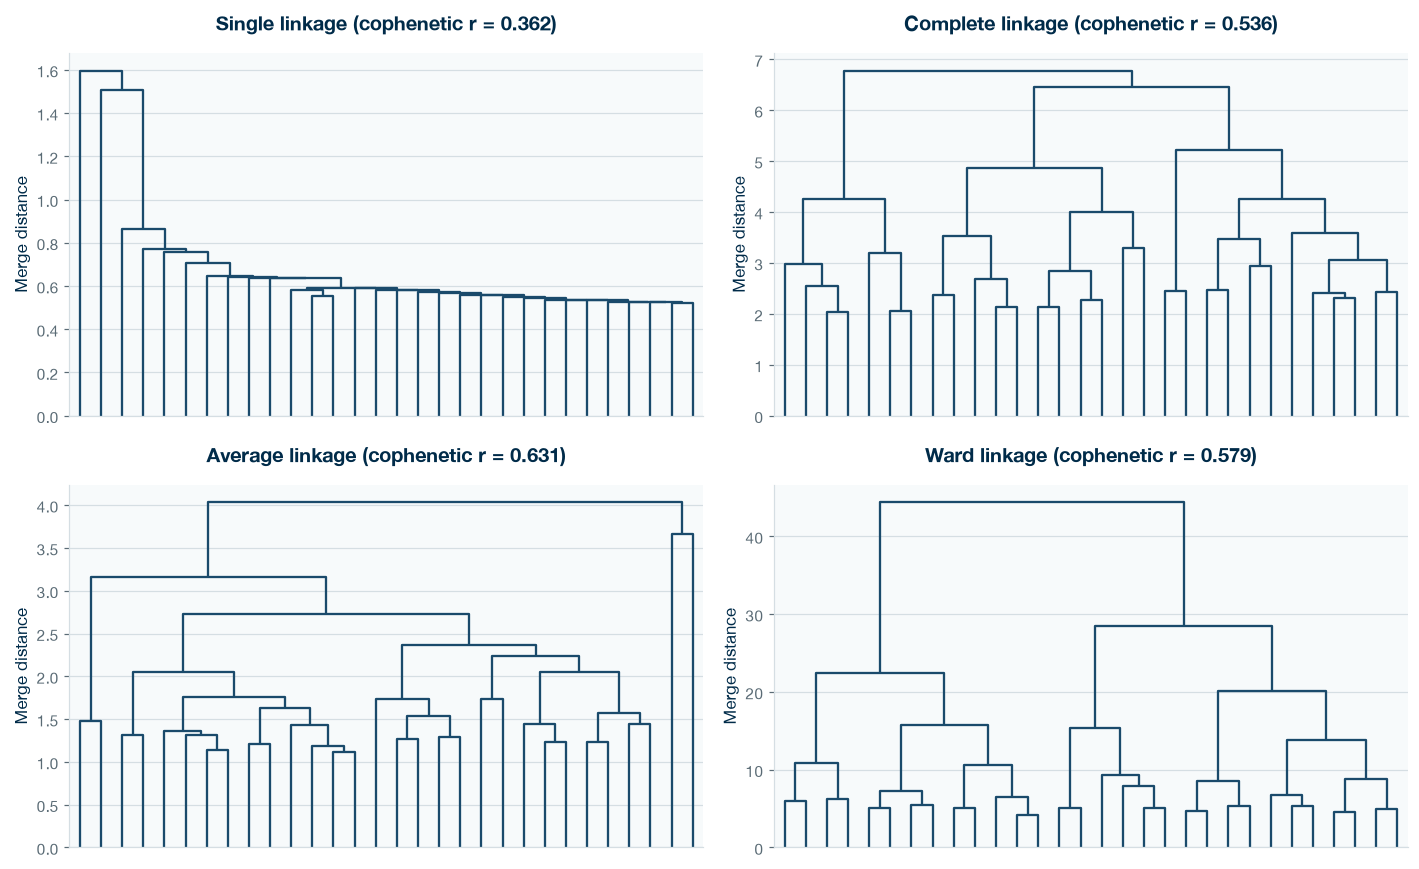

In [29]:
# Figure 8: dendrograms for the four linkages (truncated to the last 30 merges for readability)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, method in zip(axes.ravel(), linkage_methods):
    dendrogram(linkage_results[method], truncate_mode="lastp", p=30, ax=ax,
               color_threshold=0, above_threshold_color=MIDNIGHT_SOFT, no_labels=True)
    ax.set_title(method.capitalize() + " linkage (cophenetic r = "
                 + str(linkage_table.loc[method, "cophenetic_corr"]) + ")")
    ax.set_ylabel("Merge distance")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, "fig08_dendrograms_four_linkages.png")
plt.show()

Single and average linkage keep the highest cophenetic correlation but produce one giant cluster plus a few tiny ones (the "chaining" effect), which is useless for segmentation. Ward linkage merges the pair that adds the least within-cluster variance, so it produces balanced, compact groups and is the natural hierarchical counterpart to K-Means. I take Ward forward.

In [30]:
# Ward: metrics across k, then the final cut at the same k as K-Means for a fair comparison
Z_ward = linkage_results["ward"]
ward_scan = []
for k in range(2, 11):
    labels_w = fcluster(Z_ward, t=k, criterion="maxclust")
    ward_scan.append({"k": k,
                      "silhouette": round(silhouette_score(X, labels_w), 3),
                      "davies_bouldin": round(davies_bouldin_score(X, labels_w), 3),
                      "calinski_harabasz": round(calinski_harabasz_score(X, labels_w), 1)})
ward_scan = pd.DataFrame(ward_scan).set_index("k")
save_table(ward_scan, "table09_ward_k_scan.csv")

# scikit-learn's AgglomerativeClustering gives the same Ward tree with 0-based labels
ward_model = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward")
df["ward"] = ward_model.fit_predict(X)
print("Ward cluster sizes:", np.bincount(df["ward"]))
print("Agreement with K-Means (Adjusted Rand Index):", round(adjusted_rand_score(df["kmeans"], df["ward"]), 3))
ward_scan

Saved: output/tables/table09_ward_k_scan.csv
Ward cluster sizes: [358 237 235 167]
Agreement with K-Means (Adjusted Rand Index): 0.411


,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.324,1.276,488.6
3,0.276,1.265,430.9
4,0.253,1.257,402.9
5,0.241,1.159,399.3
6,0.255,1.137,382.1
7,0.244,1.087,381.0
8,0.248,1.126,381.1
9,0.244,1.153,369.5
10,0.251,1.117,363.7


Saved: output/figures/fig09_ward_dendrogram_cut.png


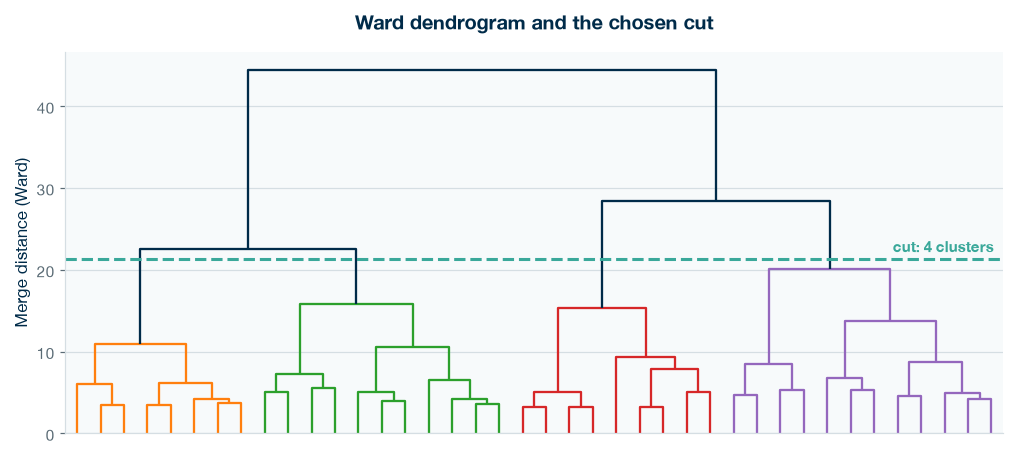

In [31]:
# Figure 9: Ward dendrogram with the cut that gives K_FINAL clusters
cut_height = (Z_ward[-K_FINAL, 2] + Z_ward[-K_FINAL + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(Z_ward, truncate_mode="lastp", p=40, ax=ax, color_threshold=cut_height,
           above_threshold_color=MIDNIGHT, no_labels=True)
ax.axhline(cut_height, color=TIFFANY_DEEP, linestyle="--", linewidth=2)
ax.text(ax.get_xlim()[1] * 0.99, cut_height * 1.04, "cut: " + str(K_FINAL) + " clusters",
        color=TIFFANY_DEEP, ha="right", fontweight="bold")
ax.set_title("Ward dendrogram and the chosen cut")
ax.set_ylabel("Merge distance (Ward)")
ax.grid(axis="x", visible=False)
save_figure(fig, "fig09_ward_dendrogram_cut.png")
plt.show()

## 8. DBSCAN

DBSCAN groups points that sit in dense regions and labels isolated points as **noise** (-1). It does not need *k*, but needs two settings: `eps` (the neighbourhood radius) and `min_samples` (how many neighbours make a point "core"). A common starting rule is `min_samples` = 2 x number of features = 6, and `eps` near the "knee" of the sorted distance to each point's *min_samples*-th nearest neighbour.

Saved: output/figures/fig10_dbscan_k_distance.png


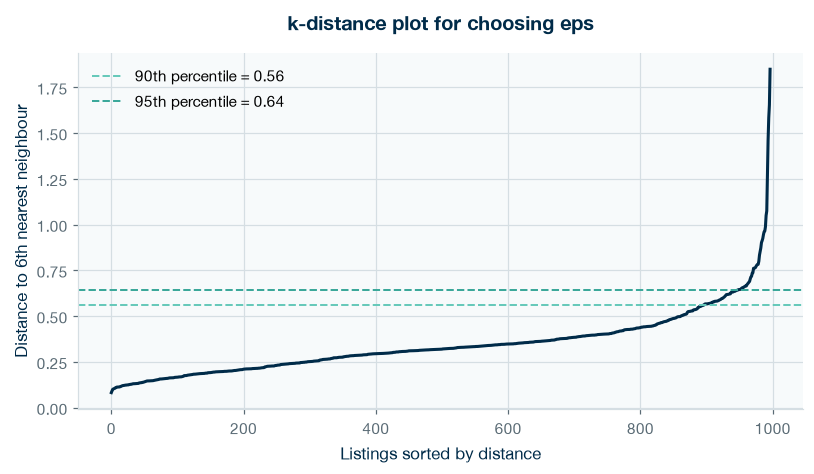

In [32]:
MIN_SAMPLES = 2 * len(FEATURES)
neighbours = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
dist_k, _ = neighbours.kneighbors(X)
k_distance = np.sort(dist_k[:, -1])

# Figure 10: k-distance plot used to pick eps
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(k_distance, color=MIDNIGHT, linewidth=2)
for q, colour in [(0.90, TIFFANY), (0.95, TIFFANY_DEEP)]:
    ax.axhline(np.quantile(k_distance, q), color=colour, linestyle="--", linewidth=1.3,
               label=str(int(q * 100)) + "th percentile = " + str(round(np.quantile(k_distance, q), 2)))
ax.set_xlabel("Listings sorted by distance")
ax.set_ylabel("Distance to " + str(MIN_SAMPLES) + "th nearest neighbour")
ax.set_title("k-distance plot for choosing eps")
ax.legend(loc="upper left")
save_figure(fig, "fig10_dbscan_k_distance.png")
plt.show()

In [33]:
# Grid search over eps and min_samples. Silhouette is computed on clustered points only,
# so it must be read together with the noise share and the number of clusters.
dbscan_rows = []
for eps in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70]:
    for min_s in [4, 6, 10, 15]:
        labels_d = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
        n_clusters = len(set(labels_d)) - (1 if -1 in labels_d else 0)
        noise_share = (labels_d == -1).mean()
        mask = labels_d != -1
        sil = np.nan
        if n_clusters >= 2:
            sil = silhouette_score(X[mask], labels_d[mask])
        dbscan_rows.append({"eps": eps, "min_samples": min_s, "clusters": n_clusters,
                            "noise_pct": round(noise_share * 100, 1),
                            "silhouette_clustered": round(sil, 3) if not np.isnan(sil) else np.nan})
dbscan_grid = pd.DataFrame(dbscan_rows)
save_table(dbscan_grid.set_index(["eps", "min_samples"]), "table10_dbscan_grid.csv")
dbscan_grid.pivot(index="eps", columns="min_samples", values="clusters")

Saved: output/tables/table10_dbscan_grid.csv


min_samples,4,6,10,15
eps,,,,
0.25,34,9,6,4
0.30,19,14,5,6
0.35,11,9,5,4
0.40,6,4,3,3
0.45,3,2,3,2
0.50,1,1,3,1
0.60,1,1,1,1
0.70,1,1,1,1


In [34]:
dbscan_grid.pivot(index="eps", columns="min_samples", values="noise_pct")

min_samples,4,6,10,15
eps,,,,
0.25,44.1,60.9,75.3,88.6
0.30,25.7,40.2,60.8,75.8
0.35,13.3,22.9,42.7,61.0
0.40,8.3,14.3,29.4,45.5
0.45,6.2,8.9,18.6,32.2
0.50,4.4,6.8,12.0,22.7
0.60,1.5,2.5,4.7,8.3
0.70,0.8,1.0,1.3,3.0


In [35]:
EPS_FINAL = 0.45
dbscan = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES)
df["dbscan"] = dbscan.fit_predict(X)
print("DBSCAN eps =", EPS_FINAL, "min_samples =", MIN_SAMPLES)
print(df["dbscan"].value_counts().sort_index())

# What do the noise points look like?  (They are the listings DBSCAN considers unusual.)
noise_profile = df.groupby(df["dbscan"] == -1)[["price", "sold", "stock_level"]].median()
noise_profile.index = ["clustered", "noise"]
noise_profile

DBSCAN eps = 0.45 min_samples = 6
dbscan
-1     89
 0    904
 1      4
Name: count, dtype: int64


,price,sold,stock_level
clustered,35.99,45.5,9.0
noise,26.11,163.0,5.0


Saved: output/figures/fig11_dbscan_clusters.png


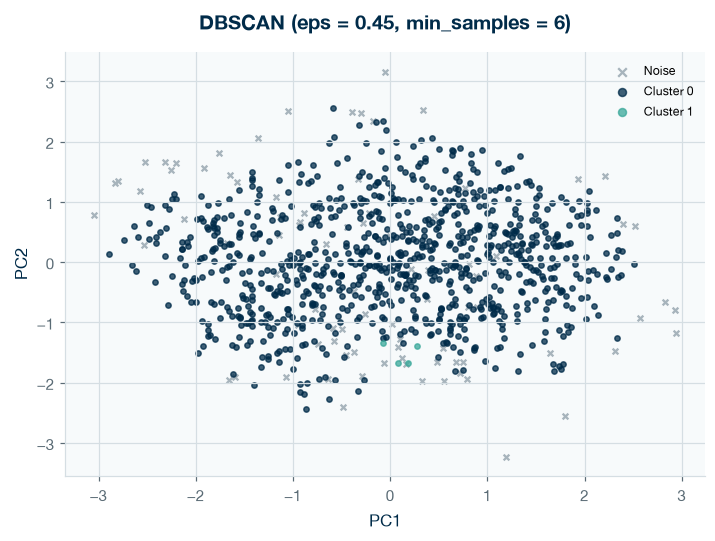

In [36]:
# Figure 11: DBSCAN result on the PCA plane
fig, ax = plt.subplots(figsize=(7.5, 5))
plot_clusters_pca(ax, df["dbscan"].values, "DBSCAN (eps = " + str(EPS_FINAL) + ", min_samples = "
                  + str(MIN_SAMPLES) + ")", noise_label=-1)
save_figure(fig, "fig11_dbscan_clusters.png")
plt.show()

**What DBSCAN tells us.** The grid (Table 10) shows only two kinds of outcome. With a small `eps`, DBSCAN breaks the data into many tiny groups and labels 40% to 90% of listings as noise. With a larger `eps`, almost everything joins one big cluster. The chosen setting (`eps` = 0.45, `min_samples` = 6, close to the 90th percentile of the k-distance curve) is the last point before everything merges: one main cluster with 90% of listings, one very small group, and 8.9% noise.

This is a finding in itself: the listings do **not** contain separate dense regions with empty space between them, which is the structure DBSCAN is designed to find. The listings it calls noise are mostly the extreme cases (very high sales, very high price, or very low stock), so DBSCAN works well as an **anomaly flag** but not as a segmentation tool for this catalogue.

## 9. Model comparison and validation

Clustering has no "correct answer" to score against, so I combine four kinds of evidence:

1. **Internal indices**: silhouette (higher is better), Davies-Bouldin (lower is better), Calinski-Harabasz (higher is better).
2. **Stability**: re-fit on 30 random 80% subsamples and measure agreement with the full-data labels using the Adjusted Rand Index (ARI, 1 = identical grouping, 0 = chance).
3. **Sensitivity**: repeat with min-max scaling and without the top 1% of sellers.
4. **Usefulness**: cluster sizes and whether every listing gets an actionable label.

In [37]:
def internal_scores(labels, ignore_noise=False):
    labels = np.asarray(labels)
    mask = np.ones(len(labels), dtype=bool)
    if ignore_noise:
        mask = labels != -1
    return {
        "silhouette": round(silhouette_score(X[mask], labels[mask]), 3),
        "davies_bouldin": round(davies_bouldin_score(X[mask], labels[mask]), 3),
        "calinski_harabasz": round(calinski_harabasz_score(X[mask], labels[mask]), 1),
    }


def bootstrap_stability(fit_function, n_runs=30, frac=0.8):
    # Fit on the full data once, then on random subsamples, and compare labels on the shared rows
    full_labels = fit_function(X)
    rng = np.random.default_rng(SEED)
    scores = []
    for run in range(n_runs):
        idx = rng.choice(len(X), size=int(frac * len(X)), replace=False)
        sub_labels = fit_function(X[idx])
        scores.append(adjusted_rand_score(full_labels[idx], sub_labels))
    return np.mean(scores), np.std(scores)


def fit_kmeans(data):
    return KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(data)


def fit_ward(data):
    return AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(data)


def fit_dbscan(data):
    return DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES).fit_predict(data)


comparison_rows = []
for name, column, fit_function, ignore_noise in [
        ("K-Means", "kmeans", fit_kmeans, False),
        ("Hierarchical (Ward)", "ward", fit_ward, False),
        ("DBSCAN", "dbscan", fit_dbscan, True)]:
    labels = df[column].values
    scores = internal_scores(labels, ignore_noise=ignore_noise)
    stab_mean, stab_std = bootstrap_stability(fit_function)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    sizes = pd.Series(labels[labels != -1]).value_counts()
    row = {"model": name, "clusters": n_clusters, "noise_pct": round((labels == -1).mean() * 100, 1)}
    row.update(scores)
    row["stability_ARI_mean"] = round(stab_mean, 3)
    row["stability_ARI_sd"] = round(stab_std, 3)
    row["smallest_cluster_pct"] = round(sizes.min() / len(labels) * 100, 1)
    row["largest_cluster_pct"] = round(sizes.max() / len(labels) * 100, 1)
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows).set_index("model")
save_table(comparison, "table11_model_comparison.csv")
comparison

Saved: output/tables/table11_model_comparison.csv


,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,stability_ARI_mean,stability_ARI_sd,smallest_cluster_pct,largest_cluster_pct
model,,,,,,,,,
K-Means,4,0.0,0.307,1.015,503.3,0.932,0.025,22.0,31.3
Hierarchical (Ward),4,0.0,0.253,1.257,402.9,0.481,0.084,16.8,35.9
DBSCAN,2,8.9,-0.014,1.172,3.5,0.749,0.063,0.4,90.7


In [38]:
# Seed stability for K-Means: does the answer change with the random start?
seed_labels = [KMeans(n_clusters=K_FINAL, n_init=20, random_state=s).fit_predict(X) for s in range(10)]
seed_ari = [adjusted_rand_score(seed_labels[0], lab) for lab in seed_labels[1:]]
print("K-Means ARI across 10 seeds: min", round(min(seed_ari), 3), "mean", round(np.mean(seed_ari), 3))

# Sensitivity 1: min-max scaling instead of z-scores (as used in the lessons)
X_minmax = MinMaxScaler().fit_transform(df[FEATURES])
km_minmax = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(X_minmax)
print("ARI z-score vs min-max K-Means:", round(adjusted_rand_score(df["kmeans"], km_minmax), 3))

# Sensitivity 2: drop the top 1% sellers and re-fit; compare labels on the remaining rows
keep = df["sold"] < df["sold"].quantile(0.99)
X_trim = StandardScaler().fit_transform(df.loc[keep, FEATURES])
km_trim = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(X_trim)
print("ARI full vs without top 1% sellers:", round(adjusted_rand_score(df.loc[keep, "kmeans"], km_trim), 3))

sensitivity = pd.DataFrame({
    "check": ["K-Means across 10 seeds (mean ARI)", "z-score vs min-max scaling (ARI)", "with vs without top 1% sellers (ARI)"],
    "ARI": [round(np.mean(seed_ari), 3),
            round(adjusted_rand_score(df["kmeans"], km_minmax), 3),
            round(adjusted_rand_score(df.loc[keep, "kmeans"], km_trim), 3)],
}).set_index("check")
save_table(sensitivity, "table12_sensitivity_checks.csv")
sensitivity

K-Means ARI across 10 seeds: min 0.951 mean 0.984
ARI z-score vs min-max K-Means: 0.492
ARI full vs without top 1% sellers: 0.937
Saved: output/tables/table12_sensitivity_checks.csv


,ARI
check,
K-Means across 10 seeds (mean ARI),0.984
z-score vs min-max scaling (ARI),0.492
with vs without top 1% sellers (ARI),0.937


Saved: output/figures/fig12_model_comparison.png


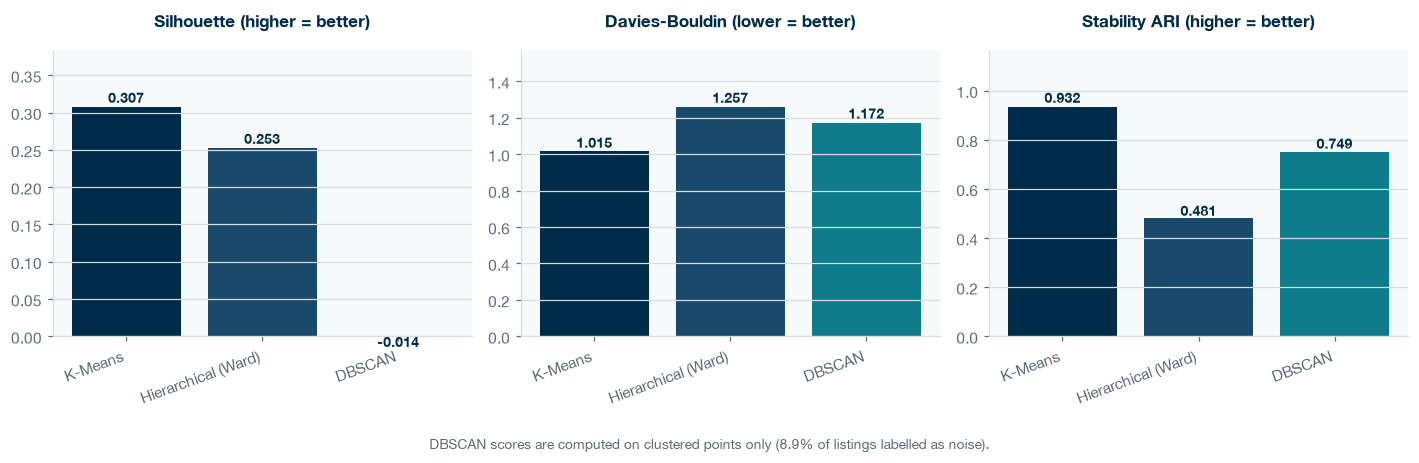

In [39]:
# Figure 12: side-by-side comparison of the three models
metrics_to_plot = [("silhouette", "Silhouette (higher = better)"),
                   ("davies_bouldin", "Davies-Bouldin (lower = better)"),
                   ("stability_ARI_mean", "Stability ARI (higher = better)")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
model_colours = [MIDNIGHT, MIDNIGHT_SOFT, TEAL]
for ax, (metric, label) in zip(axes, metrics_to_plot):
    values = comparison[metric]
    bars = ax.bar(comparison.index, values, color=model_colours)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02, str(v), ha="center",
                color=MIDNIGHT, fontsize=9, fontweight="bold")
    ax.set_title(label, fontsize=11)
    ax.set_ylim(0, max(values) * 1.25)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    ax.grid(axis="x", visible=False)
fig.text(0.5, -0.06, "DBSCAN scores are computed on clustered points only ("
         + str(comparison.loc["DBSCAN", "noise_pct"]) + "% of listings labelled as noise).",
         ha="center", color=MUTE, fontsize=9)
fig.tight_layout()
save_figure(fig, "fig12_model_comparison.png")
plt.show()

**Reading the comparison.**

- **K-Means** has the best silhouette (0.307), the lowest Davies-Bouldin (1.015) and the highest Calinski-Harabasz of the three. More importantly, it is **stable**: the grouping barely changes when 20% of the listings are removed (mean ARI 0.93), when the random seed changes (0.98), or when the top 1% of sellers are dropped (0.94).
- **Ward** produces similar-sized groups but scores lower on every index, and its grouping is **unstable** under resampling (ARI 0.48). Because every merge in a hierarchy is final, a few changed points early on can reshape the whole tree.
- **DBSCAN** does not segment this data (see Section 8). Its silhouette on clustered points is about zero, and one cluster holds 91% of listings.
- **Scaling matters.** Swapping z-scores for min-max scaling changes the K-Means grouping noticeably (ARI 0.49). Min-max gives `stock_level`, which only takes values 1 to 11, a different weight from the two log measures. I keep z-scores because they give each feature equal variance, but this is recorded as a limitation: the segment boundaries depend partly on how the features are weighted.

None of the silhouette values are high. A score around 0.3 means the clusters are real but overlapping regions of a continuum, so the segments should be treated as useful groupings for decisions, not as natural categories.

## 10. Final model and cluster profiles

**Final model: K-Means with k = 4.** On technical grounds it has the best internal scores and by far the best stability. On business grounds it puts every listing into a segment (no "noise" bucket to explain), its centroids can be read directly as a typical price, sales level and stock position, and new listings can be assigned to the nearest centroid instantly, which suits a fast-growing catalogue. Ward is kept as a cross-check (ARI with K-Means is reported in the ledger) and DBSCAN as an anomaly flag.

The profile describes each cluster in business units: typical price, typical units sold, stock position, share of all units sold, product-type mix, main brands and where listings ship from.

In [40]:
FINAL = "kmeans"
groups = df.groupby(FINAL)
profile = pd.DataFrame({
    "listings": groups.size(),
    "share_of_listings_pct": (groups.size() / len(df) * 100).round(1),
    "median_price_usd": groups["price"].median().round(2),
    "median_units_sold": groups["sold"].median().round(0),
    "mean_units_sold": groups["sold"].mean().round(0),
    "share_of_units_sold_pct": (groups["sold"].sum() / df["sold"].sum() * 100).round(1),
    "median_stock_level": groups["stock_level"].median(),
    "pct_last_one": groups["stock_level"].apply(lambda s: (s == 1).mean() * 100).round(1),
    "pct_ships_from_us": (groups["ships_from_us"].mean() * 100).round(1),
    "median_days_since_update": groups["days_since_update"].median().round(1),
})
top_type = groups["product_type"].agg(lambda s: s.value_counts().index[0])
top_type_share = groups["product_type"].agg(lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1))
profile["top_product_type"] = top_type + " (" + top_type_share.astype(str) + "%)"
profile["top_brands"] = groups["brand"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
save_table(profile, "table13_cluster_profiles.csv")
profile.T

Saved: output/tables/table13_cluster_profiles.csv


kmeans,0,1,2,3
listings,219,224,242,312
share_of_listings_pct,22.0,22.5,24.3,31.3
median_price_usd,68.99,18.99,29.94,39.99
median_units_sold,43.0,30.0,952.0,16.0
mean_units_sold,131.0,61.0,2934.0,54.0
share_of_units_sold_pct,3.7,1.8,92.3,2.2
median_stock_level,11.0,11.0,11.0,3.0
pct_last_one,0.0,0.0,1.2,14.1
pct_ships_from_us,84.9,92.0,99.6,88.5
median_days_since_update,2.1,3.1,1.1,1.6


In [41]:
# Product-type mix per cluster (row percentages)
type_mix = pd.crosstab(df[FINAL], df["product_type"], normalize="index").mul(100).round(1)
save_table(type_mix, "table14_product_type_mix.csv")
type_mix

Saved: output/tables/table14_product_type_mix.csv


product_type,Cologne,Eau de Parfum,Eau de Toilette,Generic fragrance,Other,Parfum / Extrait
kmeans,,,,,,
0,3.2,45.2,40.2,3.7,1.4,6.4
1,6.7,31.7,37.9,14.3,8.0,1.3
2,7.9,17.8,67.8,2.5,3.3,0.8
3,9.0,31.7,39.1,13.1,3.8,3.2


Saved: output/figures/fig13_cluster_profiles.png


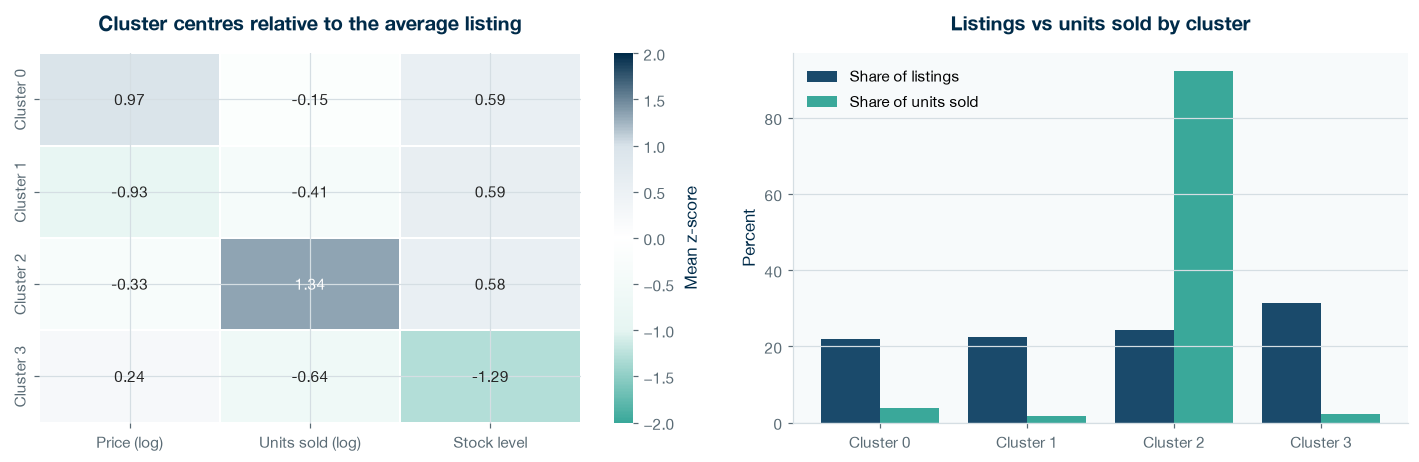

In [42]:
# Figure 13: cluster profiles as standardised feature means (how each cluster differs from the average listing)
z_profile = pd.DataFrame(X, columns=["Price (log)", "Units sold (log)", "Stock level"])
z_profile[FINAL] = df[FINAL].values
z_means = z_profile.groupby(FINAL).mean()
z_means.index = ["Cluster " + str(i) for i in z_means.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(z_means, annot=True, fmt=".2f", cmap=ARDEN_DIVERGING, center=0, vmin=-2, vmax=2,
            linewidths=1, linecolor="white", cbar_kws={"label": "Mean z-score"}, ax=axes[0])
axes[0].set_title("Cluster centres relative to the average listing")
axes[0].set_ylabel("")

share = profile[["share_of_listings_pct", "share_of_units_sold_pct"]].copy()
share.index = ["Cluster " + str(i) for i in share.index]
x_pos = np.arange(len(share))
axes[1].bar(x_pos - 0.2, share["share_of_listings_pct"], width=0.4, color=MIDNIGHT_SOFT, label="Share of listings")
axes[1].bar(x_pos + 0.2, share["share_of_units_sold_pct"], width=0.4, color=TIFFANY_DEEP, label="Share of units sold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(share.index)
axes[1].set_ylabel("Percent")
axes[1].set_title("Listings vs units sold by cluster")
axes[1].legend(loc="upper left")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, "fig13_cluster_profiles.png")
plt.show()

Saved: output/figures/fig14_cluster_distributions.png


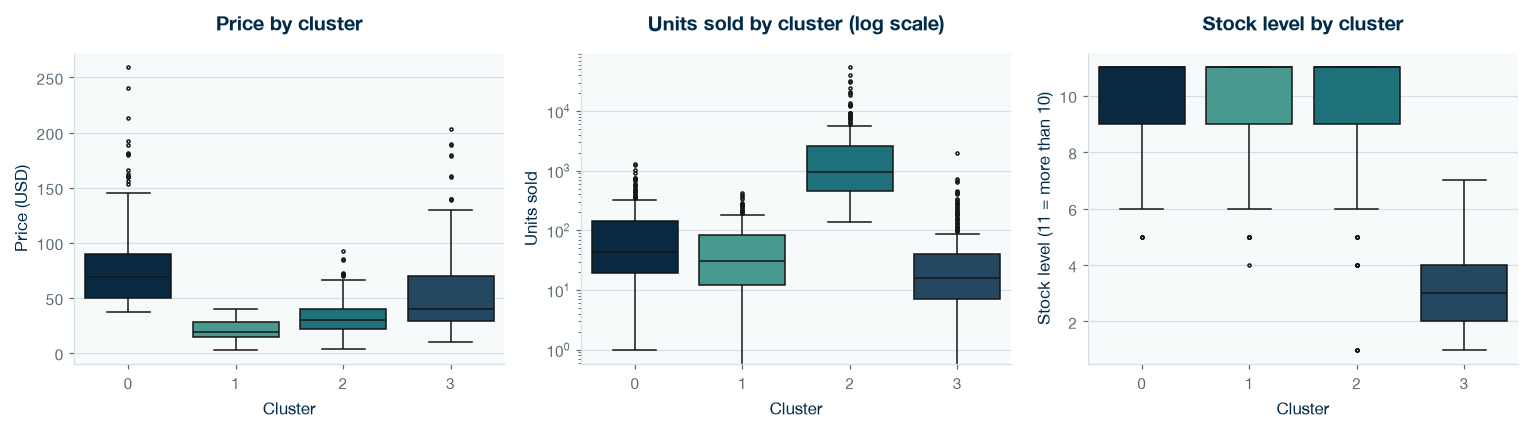

In [43]:
# Figure 14: distributions of price and units sold inside each cluster
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
order = sorted(df[FINAL].unique())
palette = [CLUSTER_COLOURS[i] for i in order]
sns.boxplot(data=df, x=FINAL, y="price", order=order, palette=palette, ax=axes[0], fliersize=2)
axes[0].set_title("Price by cluster")
axes[0].set_ylabel("Price (USD)")
sns.boxplot(data=df, x=FINAL, y="sold", order=order, palette=palette, ax=axes[1], fliersize=2)
axes[1].set_yscale("log")
axes[1].set_title("Units sold by cluster (log scale)")
axes[1].set_ylabel("Units sold")
sns.boxplot(data=df, x=FINAL, y="stock_level", order=order, palette=palette, ax=axes[2], fliersize=2)
axes[2].set_title("Stock level by cluster")
axes[2].set_ylabel("Stock level (11 = more than 10)")
for ax in axes:
    ax.set_xlabel("Cluster")
fig.tight_layout()
save_figure(fig, "fig14_cluster_distributions.png")
plt.show()

**The four segments** (numbers from Table 13):

| Cluster | Working name | Typical listing | What stands out |
|---|---|---|---|
| 2 | **Best-sellers** | about \$30, roughly 950 units sold, deep stock | 24% of listings but **92% of all units sold**; mostly Eau de Toilette (68%); almost all ship from the US |
| 0 | **Premium, slow-moving** | about \$69, around 40 sold, deep stock | Highest prices; designer Eau de Parfum (Armani, Paco Rabanne, YSL); stock is plentiful but turnover is low |
| 1 | **Budget, slow-moving** | about \$19, around 30 sold, deep stock | Cheapest listings; many unbranded or dupe-style products; low sales despite low price |
| 3 | **Low-stock** | about \$40, around 16 sold, about 3 units left | The only segment with thin stock (14% show "Last One"); these listings are close to disappearing |

These names describe the data; the business reasons behind each pattern (for example, *why* budget items sell slowly) are hypotheses to test, not findings.

In [44]:
# Save the frozen results ledger: cluster labels for every listing plus the headline numbers
df[["Item_Name", "details", "product_type", "price", "sold", "stock_level", "stock_imputed",
    "country", "kmeans", "ward", "dbscan"]].to_csv(OUTPUT_DIR / "cluster_assignments.csv", index=False)

ledger = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(df)),
    "features": FEATURES,
    "k_final": K_FINAL,
    "dbscan_eps": EPS_FINAL,
    "dbscan_min_samples": MIN_SAMPLES,
    "pca_explained_pc1_pc2": [round(float(v), 3) for v in explained[:2]],
    "comparison": comparison.reset_index().to_dict(orient="records"),
    "sensitivity": sensitivity.reset_index().to_dict(orient="records"),
    "kmeans_ward_ari": round(adjusted_rand_score(df["kmeans"], df["ward"]), 3),
    "profiles": profile.reset_index().to_dict(orient="records"),
}
with open(OUTPUT_DIR / "results_ledger.json", "w") as f:
    json.dump(ledger, f, indent=2, default=str)
print("Results ledger saved to", OUTPUT_DIR / "results_ledger.json")

Results ledger saved to output/results_ledger.json
